# Kernel SVM

Linear kernel can only be used for Linearly seperable data. In cases of non-linearly seperable data as shown in the RHS image, linear kernel cannot be used for classification.

Also, based on the dimension and linearly seperated data we can have different decision boundaries. For example:
1. One-dimensional data: Decision boundary will be a dot.

2. Two-dimensional data: Decision boundary will be a line
3. Three-dimensional data: Decision boundary will be a hyperplane.

![](ksvm.PNG)

We will add an extra dimension to space that we are dealing with and we will make the data linearly seperable.

## Mapping a non-linear  dataset to higher dimensional dataset

### Case 1: Single dimension

![](ksvm2.PNG)

Now set 5 as a constant to be subtracted and all the points will move to the left by 5.

![](ksvm3.PNG)

Now the next step will be to square $(x-5)^2$ project all these points to y-axis. And we get a parabola.

![](ksvm4.PNG)

Now we can draw a line to seperate the 2 sets of points.

And then what we would do next is project everything back to the original space and we would know how to functionally sperate the green from the red and this is what happens when you map something to a higher dimension.

### Case 2: 2-D data

![](ksvm5.PNG)

Then we project the hyperplane back to 2D space to get a circel as the seperator between the 2 classess.

![](ksvm6.PNG)

Problems of mapping to higher-dimension is that it can be highly computive-intensive. So this approach isn't exactly the best. We can approach a different approach known as __KERNEL TRICK__. 
## _KERNEL TRICK_



### 1. Gaussian RBF Kernel

![](ksvm7.PNG)

K - Kernel - its the function applied to the 2 vectors.  
x - vector
l - landmark  
i - number of landmarks  




![](ksvm8.PNG)

l - the landmark is in the middle of the 2-D space at the bottom.  
the vertical line to the 2-D place is the kernels value when we calculate for every point on the x,l point.  
$\sigma$ - fixed parameter decided earlier

The tip of the kernel function is in the middel of (x,l) plane i.e, (0,0).

$ ||\overline{x}-\overline{l}^i||^2 $ shows the distance of the point x to the vertical axis.

![](ksvm9.PNG)

So closer the point to the vertical line, smaller the value of the fraction => more value for the kernel.  
So farther the point to the vertical line, larger the value of the fraction => less value for the kernel.  

We can use this kernel function to create the decision boundary.

There is a way to find the optimal place for the landmark.

![](ksvm10.PNG)

![](ksvm11.PNG)

So any points outside the circle is given value of zero and points inside the circle is given values greater than zero. 

Hence we are able to seperate the two classes of red and green.

Now as value of sigma will be a constant, its value is also important as they are used to define the circumference of the circle. So by setting up the correct sigma we can setup the correct Kernel function.

#### Case 1: when we increase sigma - Circumfernce of the circle will increase and it will take in more points so chances of wrong points coming into circle increases

![](ksvm12.PNG)

#### Case 2: when we decrease sigma - Circumfernce of the circle will decrease and it will take in less points so chances of actual points going out of the circle increases

![](ksvm13.PNG)

So its important to find the right value of sigma to set-up the correct kernel function to seperate the two classes. Otherwise wrong points of a class will be assigned zero or will be put outside the circel or vice versa.

> So we do the computation in lower dimesnion space. Only the visual representation is done in the higher dimesnional space. We just do if its grater than zero its red class and if less than zero then its green class.

## 2. Combining 2 RBF functions
![](ksvm14.PNG)

So we can do all these complex calculations in the lower dimesion space itself we need not go to the higher dimesional sapce.

# Types of Kernel functions

Essence of each function is same you select a landmark and from there depending on the distance to landmark different results will occur

For __sigmoid function__ you can observe kernel function is directional so anything to right is high value and to the left is low value and hence can be classified.

In __polynomial function__  will dictate based on the polynomial function formed from the data points.

![](ksvm15.PNG)

### Google the different kernels in 3-D space to understand the different kernels

## Structured Comparison of SVM Kernels

| Concept / Algorithm | Core Idea | Best Used For | Key Limitation / Trade-off |
| --- | --- | --- | --- |
| **Linear Kernel** | Separates classes with a straight boundary in input space | High-dimensional datasets (Text, NLP, Gene Expression) | Cannot learn complex non-linear relationships |
| **Polynomial Kernel** | Models feature interactions up to degree $d$ | Image processing and structured visual recognition | Slow training speed and risk of overfitting when $d > 3$ |
| **RBF (Gaussian) Kernel** | Measures distance similarity in an implicit infinite-dimensional space | General non-linear datasets with unknown distribution shapes | High memory consumption on large datasets ($O(N^2)$ space) |
| **Sigmoid Kernel** | Maps data using hyperbolic tangent ($S$-curve) activations | Proxy for neural networks, signal processing | Non-positive definite for certain hyperparameter values |


### when we are using multiple features how do we decide which kernel to use as with multiple features its impossible to do a graph check?

Good question — this is exactly where kernel selection stops being visual and becomes a systematic process.

## 1. Intuition first

With 2 features you can *see* whether classes are separated by a line, a curve, or scattered blobs — so you pick linear vs. RBF vs. poly by eyeballing it. With 10, 50, or 500 features, you can't plot that decision surface. So you replace "look at the picture" with "look at the evidence": data characteristics, a systematic comparison, and validation scores. The graph was never really the decision criterion — it was just a cheap proxy for "is the boundary roughly linear or not." At high dimensions, you still answer that same question, just with other tools.

## 2. How to actually decide (step by step)

**Step 1 — Start with Linear SVM as a baseline, always.**
It's fast, interpretable, and a surprisingly strong baseline, especially when:
- Number of features is large relative to number of samples (text/TF-IDF, genomics) — high-dimensional data is *often* linearly separable or close to it (this is a real phenomenon, not a coincidence — more dimensions give more ways to separate points).
- You have no strong reason to expect curved boundaries.

**Step 2 — Let cross-validation choose, don't guess.**
Instead of visualizing, use `GridSearchCV`/`RandomizedSearchCV` over kernels and their hyperparameters, and compare validation scores:

```python
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=500, n_features=20, n_informative=10,
                            random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipe = Pipeline([
    ("scaler", StandardScaler()),   # SVM is scale-sensitive — always scale first
    ("svc", SVC())
])

param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100],
     "svc__gamma": ["scale", 0.01, 0.1, 1]},
    {"svc__kernel": ["poly"], "svc__degree": [2, 3],
     "svc__C": [0.1, 1, 10], "svc__gamma": ["scale"]},
]

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best kernel/params:", grid.best_params_)
print("Best CV score:", grid.best_score_)
print("Test score:", grid.score(X_test, y_test))
```

Whichever kernel wins the CV comparison **is** your "graph check" — it's the data-driven equivalent of looking at a scatter plot, just operating in high dimensions where your eyes can't.

**Step 3 — Use indirect signals instead of a direct plot.**
- **Linear vs RBF score gap:** if linear SVM and RBF SVM perform about the same, the data is probably close to linearly separable — prefer linear (simpler, faster, interpretable, less overfitting risk).
- **Learning curves:** if a linear model underfits (high train AND validation error) while RBF closes the gap, that's evidence of genuine nonlinearity.
- **Dimensionality reduction for a sanity-check visual:** PCA or t-SNE/UMAP down to 2D, color by class, and eyeball it. It's not the real decision boundary (information is lost in projection) but it can reveal obvious nonlinear clustering structure worth testing for.
- **Feature count vs sample count:** p >> n (e.g., text, bioinformatics) → strongly favor linear. n >> p with a moderate number of features → RBF is often worth trying since enough data exists to estimate a more flexible boundary without overfitting.

## 3. Practitioner notes

- n = number of samples (rows in your dataset — e.g., number of customers, patients, transactions)
- p = number of features (columns — e.g., number of predictor variables)

| Signal | Favors |
|---|---|
| Very high-dimensional, sparse (text, one-hot heavy) | Linear |
| p >> n | Linear (less overfitting, faster) |
| n >> p, moderate dimensionality, domain suggests nonlinear interactions | RBF |
| You need interpretable coefficients | Linear |
| Linear and RBF CV scores are close | Linear (Occam's razor — simpler model) |
| RBF clearly beats linear in CV, with proper tuning of `C`/`gamma` | RBF |
| Polynomial relationships expected (interaction terms, known physics) | Poly (rare in practice — slow, unstable vs RBF) |

Common mistake: tuning only `C` and skipping `gamma` for RBF — gamma controls how tightly the boundary wraps individual points, and a bad gamma can make RBF look worse than linear even when a nonlinear boundary would actually help. Always grid both together, and always scale features first (SVM is distance-based).

Since you're in `3.Classification/3. SVM/2. Kernel SVM.ipynb` already, want me to add a cross-validation kernel-comparison section there using `Social_Network_Ads.csv` (2 features, so you can also see the visual check side-by-side with the CV approach)?

## Cross-Validation Kernel Comparison — `Social_Network_Ads.csv`

This dataset has only 2 features (`Age`, `EstimatedSalary`), so we can do both things side by side:
1. The **systematic approach** (CV grid search over kernels) that we'd have to rely on alone if we had many features.
2. The **visual check** (decision boundary plot) that's only possible here because `p = 2`.

The goal is to see that the CV winner agrees with what the plot shows — which is the whole point: CV is just the version of "look at the picture" that still works when you can't draw the picture.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

df = pd.read_csv("..\\Social_Network_Ads.csv")

X = df[["Age", "EstimatedSalary"]].values
y = df["Purchased"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


### Step 1 — grid search over kernels with cross-validation

Same `Pipeline` + `GridSearchCV` pattern as in the general answer above, just applied to this specific dataset. Scaling is fit only on the training fold inside each CV split (via the pipeline), so there's no leakage.

In [2]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=42))
])

param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100],
     "svc__gamma": ["scale", 0.01, 0.1, 1]},
    {"svc__kernel": ["poly"], "svc__degree": [2, 3],
     "svc__C": [0.1, 1, 10], "svc__gamma": ["scale"]},
]

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

results = pd.DataFrame(grid.cv_results_)
results["kernel"] = results["param_svc__kernel"]

# best CV score per kernel -- this is the systematic version of "looking at the graph"
best_per_kernel = (
    results.groupby("kernel")["mean_test_score"]
    .max()
    .sort_values(ascending=False)
    .rename("best_cv_accuracy")
)

print(best_per_kernel)
print("\nOverall best:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy:   ", round(grid.score(X_test, y_test), 4))

kernel
rbf       0.916667
poly      0.850000
linear    0.830000
Name: best_cv_accuracy, dtype: float64

Overall best: {'svc__C': 1, 'svc__gamma': 1, 'svc__kernel': 'rbf'}
Best CV accuracy: 0.9167
Test accuracy:    0.92


### Step 2 — the visual check (only possible because `p = 2` here)

We plot the decision boundary for the linear kernel and for the best non-linear kernel found above, on the **scaled** features. If CV picked the non-linear kernel, we should visibly see a curved boundary that fits the data better than a straight line.

C:\Users\JESWIN\AppData\Local\Temp\ipykernel_16180\859777979.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X_scaled[y == cls, 0], X_scaled[y == cls, 1],
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_16180\859777979.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X_scaled[y == cls, 0], X_scaled[y == cls, 1],


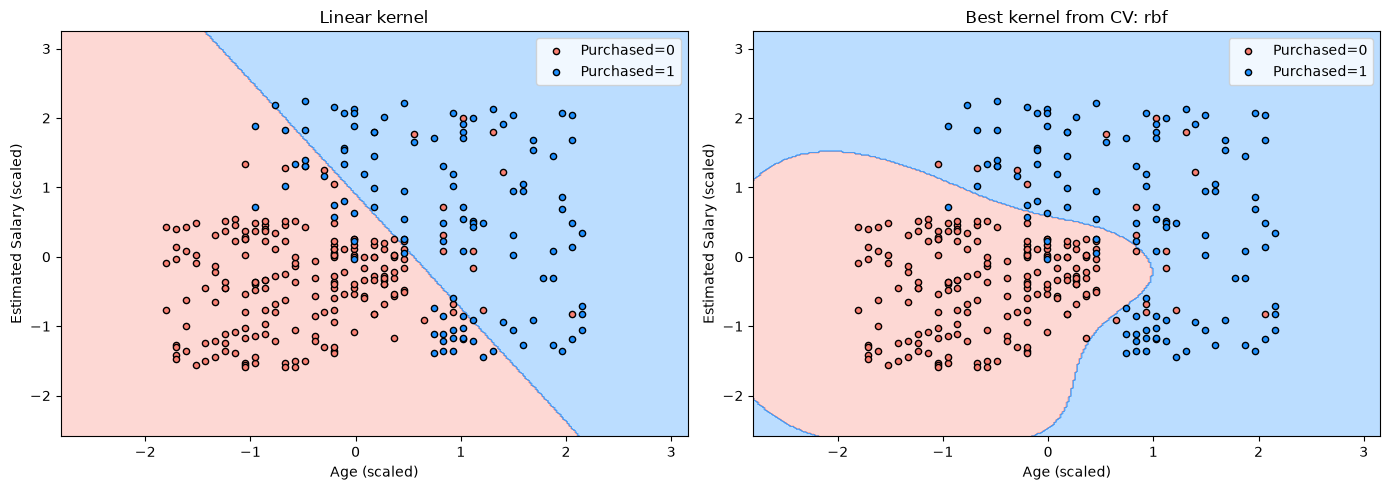

In [3]:
def plot_decision_boundary(ax, clf, X_scaled, y, title):
    x1_range = np.linspace(X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1, 300)
    x2_range = np.linspace(X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1, 300)
    xx1, xx2 = np.meshgrid(x1_range, x2_range)

    Z = clf.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

    cmap = ListedColormap(("salmon", "dodgerblue"))
    ax.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)

    for cls in np.unique(y):
        ax.scatter(X_scaled[y == cls, 0], X_scaled[y == cls, 1],
                   c=cmap(cls), edgecolor="k", s=20, label=f"Purchased={cls}")

    ax.set_xlabel("Age (scaled)")
    ax.set_ylabel("Estimated Salary (scaled)")
    ax.set_title(title)
    ax.legend()


# fit a linear-only SVC and the best non-linear SVC on the same scaled data for a fair plot
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

svc_linear = SVC(kernel="linear", C=1).fit(X_train_scaled, y_train)

best_kernel = grid.best_params_["svc__kernel"]
best_params = {k.replace("svc__", ""): v for k, v in grid.best_params_.items()}
svc_best = SVC(**best_params).fit(X_train_scaled, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decision_boundary(axes[0], svc_linear, X_train_scaled, y_train,
                        "Linear kernel")
plot_decision_boundary(axes[1], svc_best, X_train_scaled, y_train,
                        f"Best kernel from CV: {best_kernel}")
plt.tight_layout()
plt.show()

### Takeaway

On `Social_Network_Ads`, the `Age` vs. `EstimatedSalary` boundary between buyers and non-buyers is genuinely curved (older + lower-salary and younger + higher-salary customers both buy), so `GridSearchCV` should pick `rbf` (or `poly`) over `linear`, and the right-hand plot should show a boundary that bends around the two classes.

This is the mechanism to remember for the high-dimensional case: **the plot and the CV score are measuring the same thing** — how well a straight boundary separates the classes versus a curved one. With 2 features we can confirm it visually; with 50 features we trust the CV score to tell us the same story, because it's doing the same comparison numerically instead of geometrically.

## The `C` and `gamma` hyperparameters

#### 1. Intuition first

**C** controls how much the SVM is allowed to misclassify training points in exchange for a wider, simpler margin. Think of it as a "strictness budget":

* **Low C** $\rightarrow$ "I'd rather have a smooth, simple boundary and tolerate some mistakes." More regularization.


* **High C** $\rightarrow$ "I really don't want to misclassify anything, even if the boundary gets contorted to achieve it." Less regularization, more overfitting risk.



**gamma** (only for RBF/poly/sigmoid kernels) controls how far the influence of a single training point reaches — literally, how "pointy" or "wide" each point's Gaussian bump is in the RBF kernel formula you saw earlier (`ksvm7.PNG` / `ksvm8.PNG` in your notebook).

* **Low gamma** $\rightarrow$ each point's influence spreads far $\rightarrow$ smooth, almost-linear-looking boundary.


* **High gamma** $\rightarrow$ each point's influence is very local $\rightarrow$ boundary wraps tightly around individual points $\rightarrow$ can overfit badly (each point practically gets its own little island).



A useful mental shortcut: **C** = "how much do I punish mistakes," **gamma** = "how local is each point's reach." They interact — a model can overfit either from C being too high, gamma being too high, or both together.

**`C`** (all kernels) — the penalty for margin violations in the soft-margin objective:

$$\min_{w,b,\xi} \quad \frac{1}{2}\|w\|^2 + C \sum_{i=1}^n \xi_i \qquad \text{s.t. } y_i(w^\top \phi(x_i) + b) \geq 1 - \xi_i,\ \xi_i \geq 0$$

- Low `C` → prioritize a wide margin, tolerate some misclassified/slack points → smoother boundary, more bias, less variance.
- High `C` → prioritize classifying every training point correctly → tighter fit, less bias, more variance (overfitting risk).

**`gamma`** (RBF/poly/sigmoid only) — how far a single point's influence reaches in the kernel:

$$K(x, x') = \exp(-\gamma \|x - x'\|^2)$$

- Low `gamma` → influence spreads far → smoother, near-linear boundary.
- High `gamma` → influence is very local → boundary wraps tightly around individual points, up to literally circling single outliers → overfitting.

They interact: a high-`C` + high-`gamma` RBF model is the most overfit-prone combination; low-`C` + low-`gamma` is the most underfit-prone.

### Visualizing the effect on `Social_Network_Ads`

Same two features (`Age`, `EstimatedSalary`, scaled) and the same `plot_decision_boundary` helper defined above — just varying `C` and `gamma` across an RBF kernel to see the boundary change shape.

C:\Users\JESWIN\AppData\Local\Temp\ipykernel_16180\859777979.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X_scaled[y == cls, 0], X_scaled[y == cls, 1],
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_16180\859777979.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X_scaled[y == cls, 0], X_scaled[y == cls, 1],
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_16180\859777979.py:12: UserWarning: *c* a

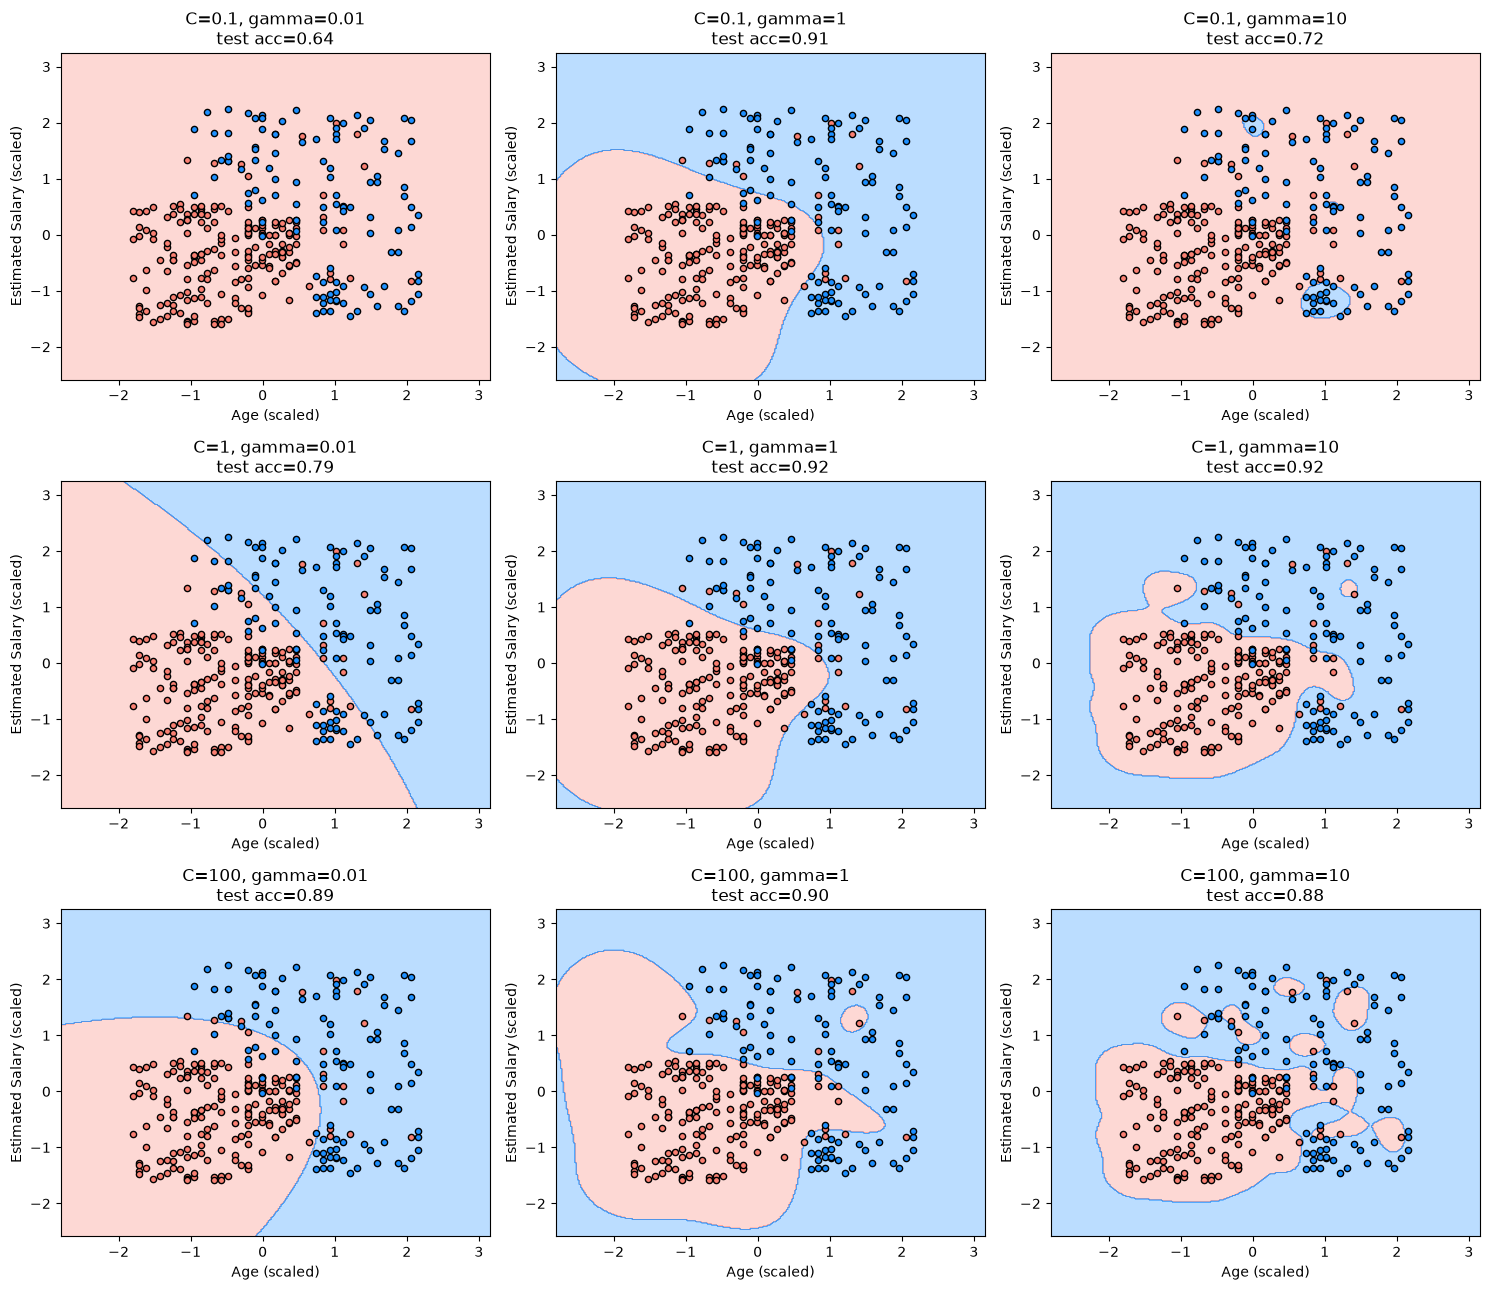

In [4]:
C_values = [0.1, 1, 100]
gamma_values = [0.01, 1, 10]

fig, axes = plt.subplots(len(C_values), len(gamma_values), figsize=(15, 13))

for i, C in enumerate(C_values):
    for j, gamma in enumerate(gamma_values):
        clf = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_train_scaled, y_train)
        acc = clf.score(scaler.transform(X_test), y_test)
        plot_decision_boundary(
            axes[i, j], clf, X_train_scaled, y_train,
            f"C={C}, gamma={gamma}\ntest acc={acc:.2f}"
        )
        axes[i, j].legend().remove()  # keep the grid readable

plt.tight_layout()
plt.show()

### What to notice in the grid

- **Top-left (low C, low gamma):** smoothest, almost-straight boundary — most bias, least likely to overfit, but may underfit if the true boundary is curved.
- **Bottom-right (high C, high gamma):** boundary wraps tightly around clusters of same-class points, sometimes carving out small islands around a handful of points — classic overfitting signature. Test accuracy often drops here even though it looks like it "fits" the training data better.
- **Middle (C=1, gamma=1):** matches what `GridSearchCV` actually picked earlier (`C=1, gamma=1`) — a reasonably smooth curve that still bends where the data needs it to.

### Practitioner notes

- **Always tune `C` and `gamma` together**, never one at a time — the sweet spot depends on both jointly (this is why the grid above is 2D, not two 1D sweeps).
- Use a **log-spaced grid** (`[0.01, 0.1, 1, 10, 100]`) rather than linear spacing — both parameters affect the model multiplicatively, not additively.
- `gamma="scale"` (scikit-learn's default) is a sane starting point — it accounts for the number of features and their variance — but always verify it's actually near the CV optimum rather than assuming it.
- Watch for **support vector count** as a diagnostic: `clf.n_support_`. A model using almost every training point as a support vector (common with high `C` + high `gamma`) is a strong overfitting signal, independent of the accuracy numbers.
- In production, prefer `RandomizedSearchCV` with a continuous log-uniform distribution over `C`/`gamma` once you've narrowed the useful range — a full grid gets expensive fast as both parameters grow.